In [ ]:
!pip install prophet openpyxl matplotlib pandas numpy scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Simparda 2024.xlsx to Simparda 2024.xlsx
Saving Simparda 2025.xlsx to Simparda 2025.xlsx


In [ ]:
xls2024 = pd.ExcelFile("Simparda 2024.xlsx")
print(xls2024.sheet_names)

xls2025 = pd.ExcelFile("Simparda 2025.xlsx")
print(xls2025.sheet_names)

['Table 1']
['Table 1', 'Table 2']


In [ ]:
df2024 = pd.read_excel(
    "Simparda 2024.xlsx",
    sheet_name="Table 1",
    header=None
)

df2025 = pd.read_excel(
    "Simparda 2025.xlsx",
    sheet_name="Table 1",
    header=None
)

In [ ]:
print(df2024.head(10))

                                                  0                       1   \
0     LAPORAN DATA PARIWISATA DAERAH PROVINSI BANTEN                     NaN   
1  Wilayah                                 :  Kab...                     NaN   
2                                                No.  Nama Lokasi Pariwisata   
3                                                NaN                     NaN   
4                               Kabupaten Pandeglang                     NaN   
5                                                  1            Janur Kuning   
6                                                  2      Pondok Parahyangan   
7                                                  3     Asoka Resort Banten   
8                                                  4             Archipelago   
9                                                  5            Baitul Hamdi   

                2                                                  3   \
0              NaN                            

In [ ]:
bulan_2024 = []
kunjungan_2024 = []

for i in range(12):

    col_nus = 4 + (i * 2)
    col_man = col_nus + 1

    nus = pd.to_numeric(
        df2024.iloc[4, col_nus],
        errors='coerce'
    )

    man = pd.to_numeric(
        df2024.iloc[4, col_man],
        errors='coerce'
    )

    total = nus + man

    tanggal = pd.to_datetime(
        df2024.iloc[2, col_nus]
    )

    bulan_2024.append(tanggal)
    kunjungan_2024.append(total)

df_ts_2024 = pd.DataFrame({
    "Tanggal": bulan_2024,
    "Total_Kunjungan": kunjungan_2024
})

df_ts_2024

,Tanggal,Total_Kunjungan
0,2024-01-01,403525
1,2024-02-01,168319
2,2024-03-01,118344
3,2024-04-01,474332
4,2024-05-01,155089
5,2024-06-01,151380
6,2024-07-01,158203
7,2024-08-01,172340
8,2024-09-01,166386
9,2024-10-01,138389


In [ ]:
bulan_2025 = []
kunjungan_2025 = []

for i in range(12):

    col_nus = 4 + (i * 2)
    col_man = col_nus + 1

    nus = pd.to_numeric(
        df2025.iloc[4, col_nus],
        errors='coerce'
    )

    man = pd.to_numeric(
        df2025.iloc[4, col_man],
        errors='coerce'
    )

    total = nus + man

    tanggal = pd.to_datetime(
        df2025.iloc[2, col_nus]
    )

    bulan_2025.append(tanggal)
    kunjungan_2025.append(total)

df_ts_2025 = pd.DataFrame({
    "Tanggal": bulan_2025,
    "Total_Kunjungan": kunjungan_2025
})

df_ts_2025

,Tanggal,Total_Kunjungan
0,2025-01-01,179654
1,2025-02-01,152081
2,2025-03-01,121227
3,2025-04-01,665856
4,2025-05-01,214924
5,2025-06-01,169407
6,2025-07-01,171738
7,2025-08-01,183133
8,2025-09-01,178782
9,2025-10-01,162955


In [ ]:
df = pd.concat(
    [df_ts_2024, df_ts_2025],
    ignore_index=True
)

df = df.sort_values("Tanggal")

df.reset_index(
    drop=True,
    inplace=True
)

df

,Tanggal,Total_Kunjungan
0,2024-01-01,403525
1,2024-02-01,168319
2,2024-03-01,118344
3,2024-04-01,474332
4,2024-05-01,155089
5,2024-06-01,151380
6,2024-07-01,158203
7,2024-08-01,172340
8,2024-09-01,166386
9,2024-10-01,138389


In [ ]:
print(df.shape)

(24, 2)


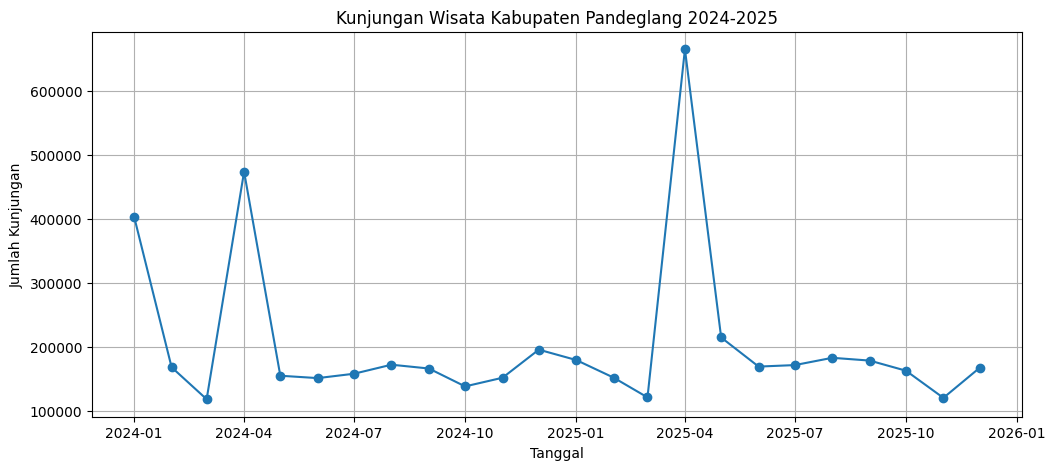

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    df["Tanggal"],
    df["Total_Kunjungan"],
    marker="o"
)

plt.title(
    "Kunjungan Wisata Kabupaten Pandeglang 2024-2025"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Kunjungan")

plt.grid(True)

plt.show()

In [ ]:
train_size = int(len(prophet_df)*0.75)

train = prophet_df[:train_size]

test = prophet_df[train_size:]

NameError: name 'prophet_df' is not defined

In [ ]:
print(df.head())
print(df.shape)

     Tanggal  Total_Kunjungan
0 2024-01-01           403525
1 2024-02-01           168319
2 2024-03-01           118344
3 2024-04-01           474332
4 2024-05-01           155089
(24, 2)


In [ ]:
%whos

Variable              Type         Data/Info
--------------------------------------------
Prophet               type         <class 'prophet.forecaster.Prophet'>
bulan_2024            list         n=12
bulan_2025            list         n=12
col_man               int          27
col_nus               int          26
df                    DataFrame          Tanggal  Total_Kunj<...>25-12-01           167456
df2024                DataFrame                             <...>\n[368 rows x 30 columns]
df2025                DataFrame                             <...>n\n[51 rows x 30 columns]
df_ts_2024            DataFrame          Tanggal  Total_Kunj<...>24-12-01           195879
df_ts_2025            DataFrame          Tanggal  Total_Kunj<...>25-12-01           167456
files                 module       <module 'google.colab.fil<...>s/google/colab/files.py'>
i                     int          11
kunjungan_2024        list         n=12
kunjungan_2025        list         n=12
man               

In [ ]:
prophet_df = df.rename(
    columns={
        'Tanggal':'ds',
        'Total_Kunjungan':'y'
    }
)

print(prophet_df.head())

          ds       y
0 2024-01-01  403525
1 2024-02-01  168319
2 2024-03-01  118344
3 2024-04-01  474332
4 2024-05-01  155089


In [ ]:
train_size = int(len(prophet_df) * 0.75)

train = prophet_df.iloc[:train_size]

test = prophet_df.iloc[train_size:]

print("Train:", len(train))
print("Test :", len(test))

Train: 18
Test : 6


In [ ]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model.fit(train)

INFO:prophet:n_changepoints greater than number of observations. Using 13.


In [ ]:
future_test = model.make_future_dataframe(
    periods=6,
    freq='MS'
)

forecast_test = model.predict(future_test)

In [ ]:
forecast_test[['ds','yhat']].tail(6)

,ds,yhat
18,2025-07-01,487269.043432
19,2025-08-01,-110608.528717
20,2025-09-01,68367.655519
21,2025-10-01,671348.368120
22,2025-11-01,1054.653631
23,2025-12-01,85967.259206


In [ ]:
pred_test = forecast_test[
    ['ds','yhat']
].tail(len(test))

pred_test

,ds,yhat
18,2025-07-01,487269.043432
19,2025-08-01,-110608.528717
20,2025-09-01,68367.655519
21,2025-10-01,671348.368120
22,2025-11-01,1054.653631
23,2025-12-01,85967.259206


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test['y'],
    pred_test['yhat']
)

rmse = np.sqrt(
    mean_squared_error(
        test['y'],
        pred_test['yhat']
    )
)

print("MAE :", round(mae,2))
print("RMSE :", round(rmse,2))

MAE : 238160.9
RMSE : 282074.15


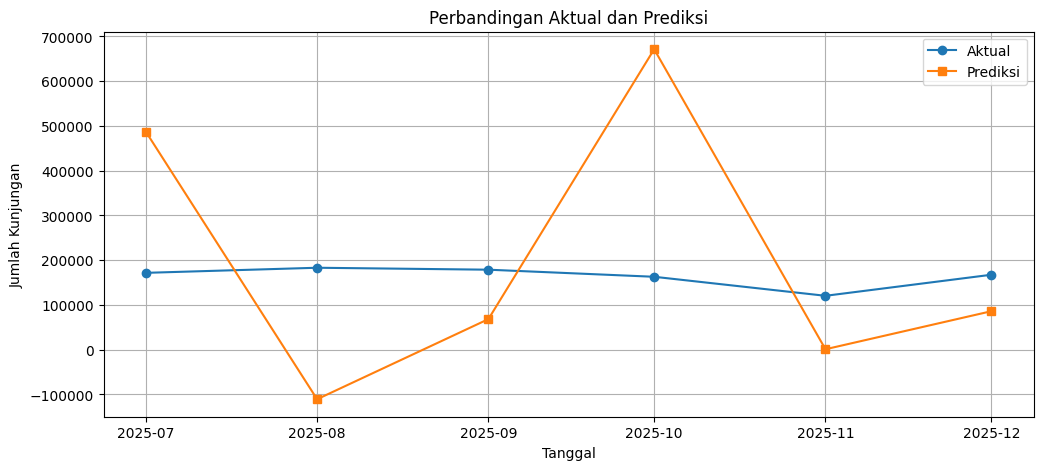

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    test['ds'],
    test['y'],
    marker='o',
    label='Aktual'
)

plt.plot(
    pred_test['ds'],
    pred_test['yhat'],
    marker='s',
    label='Prediksi'
)

plt.title('Perbandingan Aktual dan Prediksi')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Kunjungan')
plt.legend()
plt.grid()

plt.show()

In [ ]:
model_final = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model_final.fit(prophet_df)

INFO:prophet:n_changepoints greater than number of observations. Using 18.


In [ ]:
future = model_final.make_future_dataframe(
    periods=12,
    freq='MS'
)

forecast = model_final.predict(future)

In [ ]:
prediksi_2026 = forecast[
    ['ds','yhat']
].tail(12)

prediksi_2026

,ds,yhat
24,2026-01-01,296685.125741
25,2026-02-01,200703.254478
26,2026-03-01,-13246.368579
27,2026-04-01,754915.173040
28,2026-05-01,207575.271335
29,2026-06-01,159269.120439
30,2026-07-01,187405.858825
31,2026-08-01,213597.274774
32,2026-09-01,217659.128864
33,2026-10-01,206155.494255


In [ ]:
prediksi_2026.to_excel(
    "Prediksi_Kunjungan_Wisata_2026.xlsx",
    index=False
)

print("Berhasil disimpan")

Berhasil disimpan


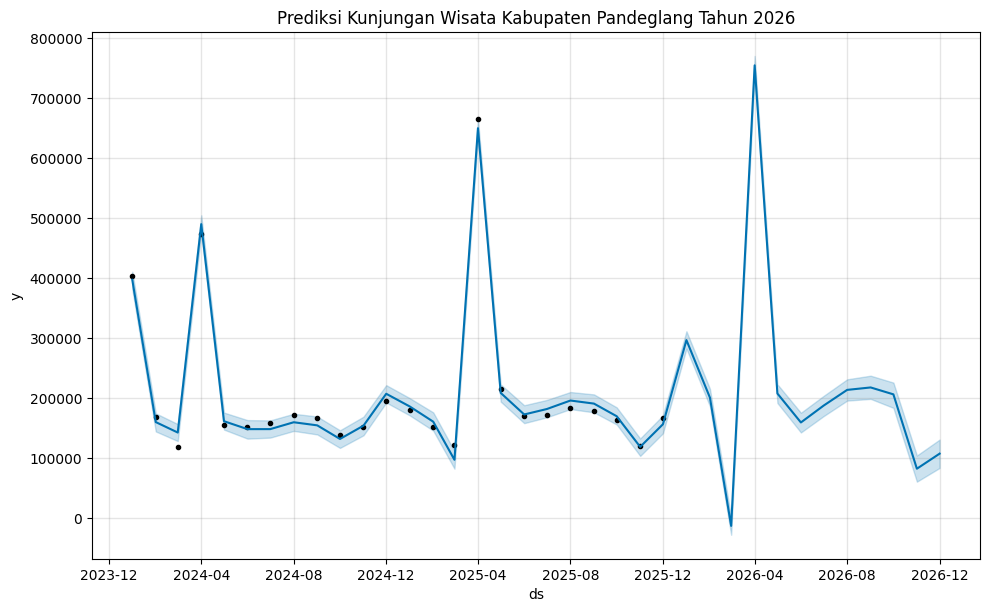

In [ ]:
fig = model_final.plot(forecast)

plt.title(
    "Prediksi Kunjungan Wisata Kabupaten Pandeglang Tahun 2026"
)

plt.show()

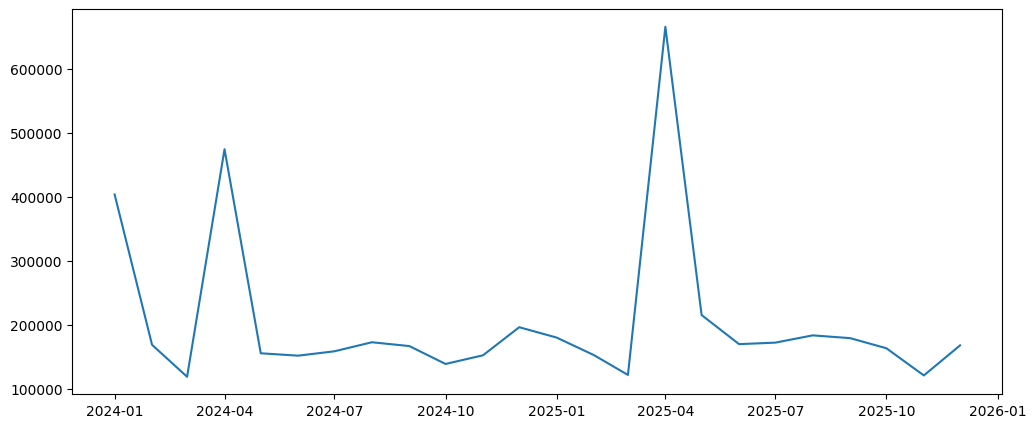

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(prophet_df['ds'], prophet_df['y'])
plt.show()

In [ ]:
prophet_df.describe()

,ds,y
count,24,24.000000
mean,2024-12-15 22:00:00,205908.625000
min,2024-01-01 00:00:00,118344.000000
25%,2024-06-23 12:00:00,152050.000000
50%,2024-12-16 12:00:00,167887.500000
75%,2025-06-08 12:00:00,180523.750000
max,2025-12-01 00:00:00,665856.000000
std,NaN,127696.420685


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(
    test['y'],
    pred_test['yhat']
)

print("MAPE :", round(mape*100,2), "%")

MAPE : 144.28 %


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model_hw = ExponentialSmoothing(
    train['y'],
    trend='add',
    seasonal=None
)

fit_hw = model_hw.fit()

pred_hw = fit_hw.forecast(len(test))

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

import numpy as np

mae_hw = mean_absolute_error(
    test['y'],
    pred_hw
)

rmse_hw = np.sqrt(
    mean_squared_error(
        test['y'],
        pred_hw
    )
)

mape_hw = mean_absolute_percentage_error(
    test['y'],
    pred_hw
)

print("MAE :", mae_hw)
print("RMSE :", rmse_hw)
print("MAPE :", mape_hw*100)

MAE : 14958.401482378453
RMSE : 17611.320755419514
MAPE : 9.966180228640685


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model_final = ExponentialSmoothing(
    prophet_df['y'],
    trend='add',
    seasonal=None
)

fit_final = model_final.fit()

In [ ]:
forecast_2026 = fit_final.forecast(12)

forecast_2026

,0
24,134352.218081
25,127238.824351
26,120125.430621
27,113012.036891
28,105898.643161
29,98785.249431
30,91671.855701
31,84558.461971
32,77445.068241
33,70331.674511


In [ ]:
prediksi_2026 = pd.DataFrame({
    'Tanggal': pd.date_range(
        start='2026-01-01',
        periods=12,
        freq='MS'
    ),
    'Prediksi_Kunjungan': forecast_2026.values
})

prediksi_2026

,Tanggal,Prediksi_Kunjungan
0,2026-01-01,134352.218081
1,2026-02-01,127238.824351
2,2026-03-01,120125.430621
3,2026-04-01,113012.036891
4,2026-05-01,105898.643161
5,2026-06-01,98785.249431
6,2026-07-01,91671.855701
7,2026-08-01,84558.461971
8,2026-09-01,77445.068241
9,2026-10-01,70331.674511


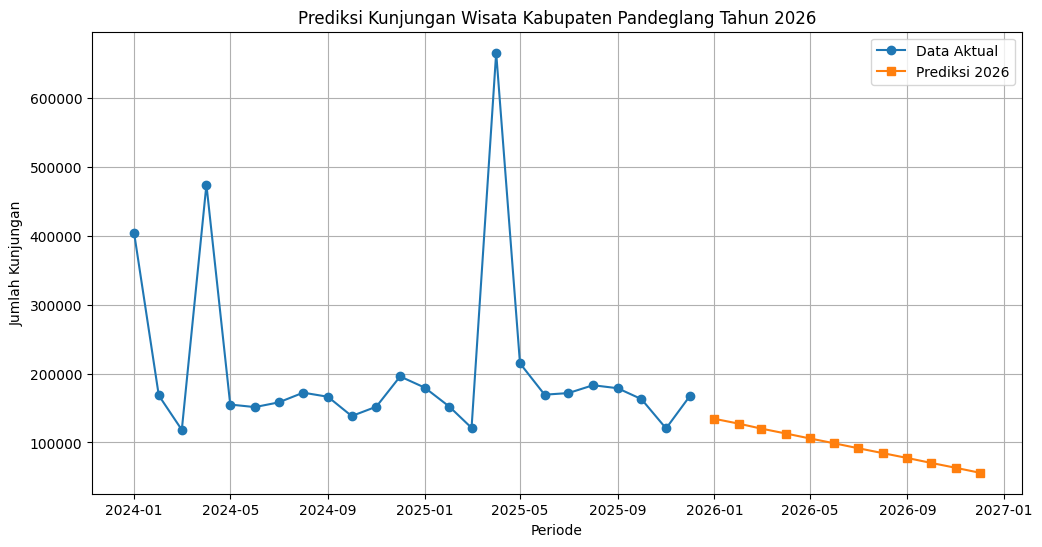

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    prophet_df['ds'],
    prophet_df['y'],
    marker='o',
    label='Data Aktual'
)

plt.plot(
    prediksi_2026['Tanggal'],
    prediksi_2026['Prediksi_Kunjungan'],
    marker='s',
    label='Prediksi 2026'
)

plt.title('Prediksi Kunjungan Wisata Kabupaten Pandeglang Tahun 2026')
plt.xlabel('Periode')
plt.ylabel('Jumlah Kunjungan')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
prediksi_2026.to_excel(
    "Prediksi_Kunjungan_Wisata_Pandeglang_2026.xlsx",
    index=False
)

print("File berhasil disimpan")

File berhasil disimpan
